In [43]:
import numpy as np
import matplotlib.pyplot as plt
import time

In [44]:
# Sử dụng hàm convolve2d của Gấm
def convolve2d(image, kernel, padding="constant"):
    image = np.asarray(image, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)

    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("Image và kernel phải là mảng 2 chiều")

    kh, kw = kernel.shape

    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("Kernel phải có kích thước lẻ")

    if padding not in ("constant", "reflect", "edge"):
        raise ValueError("Padding không hợp lệ")

    ph, pw = kh // 2, kw // 2

    padded = np.pad(
        image,
        ((ph, ph), (pw, pw)),
        mode=padding
    )

    flipped = np.flip(kernel, axis=(0, 1))

    h, w = image.shape
    output = np.zeros((h, w), dtype=np.float64)

    for i in range(h):
        for j in range(w):
            region = padded[i:i+kh, j:j+kw]
            output[i, j] = np.sum(region * flipped)

    return output

## Tấn Lên – Demo 3b: Phát hiện biên Sobel và Làm sắc nét ảnh

**Mục tiêu:**
- Áp dụng các kernel Sobel X và Sobel Y để tính toán gradient của ảnh.
- Tính toán độ lớn và hướng của gradient.
- Áp dụng toán tử Laplacian để làm sắc nét ảnh.
- Trực quan hóa và phân tích kết quả xử lý.

Các thí nghiệm sử dụng hàm `convolve2d` của nhóm để thực hiện phép chập với các kernel khác nhau.

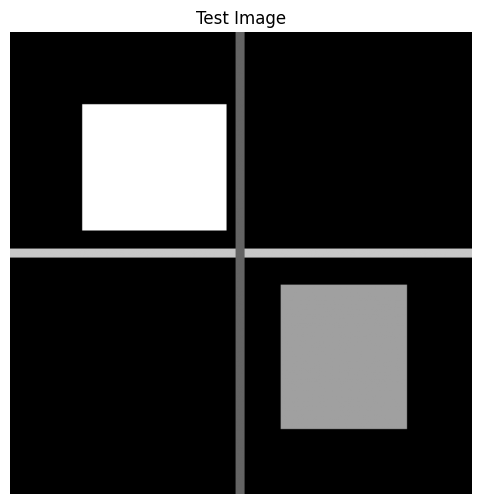

In [45]:
#  Tạo ảnh thử nghiệm 
height, width = 256, 256
img_demo = np.zeros((height, width), dtype=np.uint8)

# Add bright and gray rectangles
img_demo[40:110, 40:120] = 255
img_demo[140:220, 150:220] = 160

# Add horizontal and vertical structures
img_demo[120:125, :] = 200
img_demo[:, 125:130] = 100

# Display the test image
plt.figure(figsize=(6, 6))
plt.imshow(img_demo, cmap="gray", vmin=0, vmax=255)
plt.title("Test Image")
plt.axis("off")
plt.show()

In [46]:
 
# Sobel edge detection

img_float = img_demo.astype(np.float64)

sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float64)

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float64)

# convolve2d thực hiện tích chập thật nên cần lật kernel
sobel_x_conv = np.flip(sobel_x, axis=(0, 1))
sobel_y_conv = np.flip(sobel_y, axis=(0, 1))

gx = convolve2d(
    img_float, sobel_x_conv, padding="reflect"
)

gy = convolve2d(
    img_float, sobel_y_conv, padding="reflect"
)

edge_magnitude = np.sqrt(gx**2 + gy**2)

edge_direction = np.degrees(
    np.arctan2(gy, gx)
)

print("Sobel completed!")
print("gx:", gx.shape)
print("gy:", gy.shape)
 

Sobel completed!
gx: (256, 256)
gy: (256, 256)


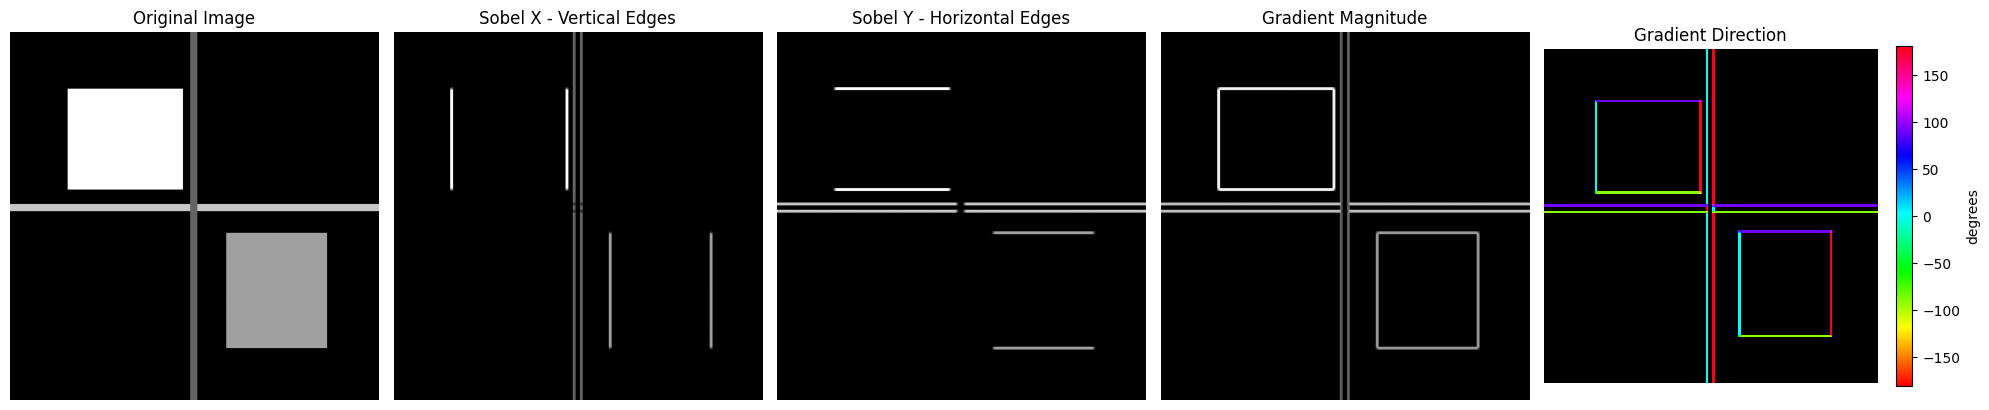

In [47]:
 
# Visualize Sobel edge detection

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

axes[0].imshow(img_demo, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(np.abs(gx), cmap="gray")
axes[1].set_title("Sobel X - Vertical Edges")

axes[2].imshow(np.abs(gy), cmap="gray")
axes[2].set_title("Sobel Y - Horizontal Edges")

axes[3].imshow(edge_magnitude, cmap="gray")
axes[3].set_title("Gradient Magnitude")

# Chỉ tô màu hướng ở pixel có cạnh; vùng phẳng (gx = gy = 0) để đen
direction_display = np.where(edge_magnitude > 0, edge_direction, np.nan)
direction_cmap = plt.get_cmap("hsv").copy()
direction_cmap.set_bad("black")
im = axes[4].imshow(direction_display, cmap=direction_cmap, vmin=-180, vmax=180,
                    interpolation="nearest")
axes[4].set_title("Gradient Direction")
fig.colorbar(im, ax=axes[4], fraction=0.046, label="degrees")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

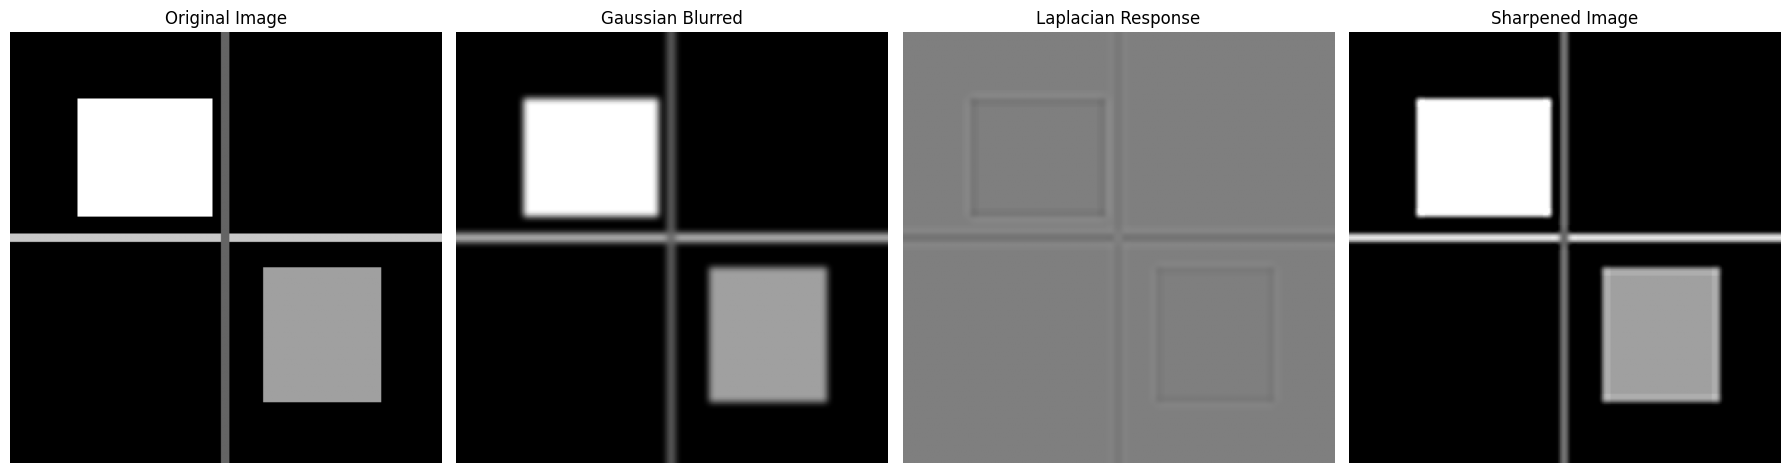

In [48]:
# Convert original image to float64
img_float = img_demo.astype(np.float64)

# Kernel Gauss tự viết, làm mờ bằng convolve2d của nhóm
def gaussian_kernel(size, sigma):
    r = size // 2
    y, x = np.mgrid[-r:r + 1, -r:r + 1]
    kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))
    return kernel / kernel.sum()

# Blur the image first to make the sharpening effect more visible
img_blurred = convolve2d(
    img_float,
    gaussian_kernel(9, 2.0),
    padding="reflect"
)

# 4-neighbor Laplacian kernel
laplacian_kernel = np.array([
    [ 0,  1,  0],
    [ 1, -4,  1],
    [ 0,  1,  0]
], dtype=np.float64)

# Apply Laplacian to the blurred image
laplacian = convolve2d(
    img_blurred,
    laplacian_kernel,
    padding="reflect"
)

# Sharpen the blurred image
alpha = 3.0
sharpened_float = img_blurred - alpha * laplacian

# Clip to valid image range
sharpened = np.clip(
    np.round(sharpened_float), 0, 255
).astype(np.uint8)

# Convert for display
img_blurred_display = np.clip(
    np.round(img_blurred), 0, 255
).astype(np.uint8)

laplacian_display = np.clip(
    127.5 + laplacian / 2, 0, 255
).astype(np.uint8)

# Compare original, blurred, Laplacian and sharpened images
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(img_demo, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Image")

axes[1].imshow(
    img_blurred_display, cmap="gray", vmin=0, vmax=255
)
axes[1].set_title("Gaussian Blurred")

axes[2].imshow(
    laplacian_display, cmap="gray", vmin=0, vmax=255
)
axes[2].set_title("Laplacian Response")

axes[3].imshow(sharpened, cmap="gray", vmin=0, vmax=255)
axes[3].set_title("Sharpened Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

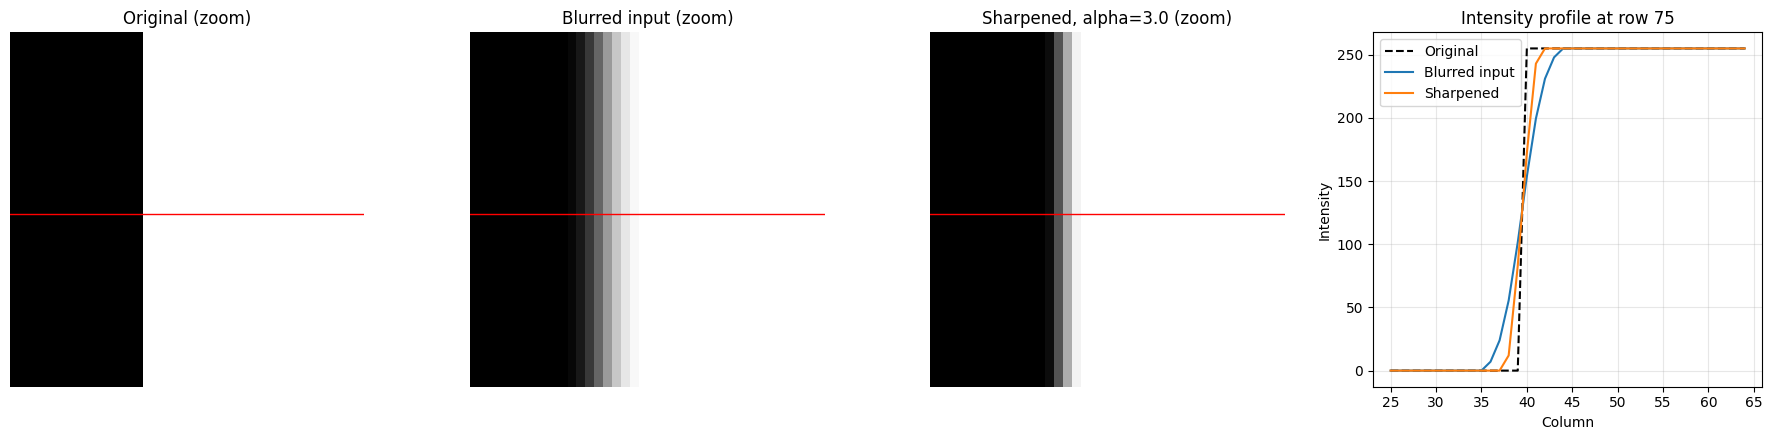

Edge width - blurred:   4 px
Edge width - sharpened: 2 px


In [49]:
# Phóng to vùng cạnh để so sánh gốc / mờ / sắc nét
r0, r1, c0, c1 = 55, 95, 25, 65   # vùng quanh cạnh trái của hình chữ nhật sáng
row = 75                          # hàng dùng để vẽ mặt cắt cường độ

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

for ax, im, title in zip(
    axes[:3],
    [img_demo, img_blurred_display, sharpened],
    ["Original (zoom)", "Blurred input (zoom)", f"Sharpened, alpha={alpha} (zoom)"]
):
    ax.imshow(im[r0:r1, c0:c1], cmap="gray", vmin=0, vmax=255,
              interpolation="nearest")
    ax.axhline(row - r0, color="red", linewidth=1)
    ax.set_title(title)
    ax.axis("off")

cols = np.arange(c0, c1)
axes[3].plot(cols, img_demo[row, c0:c1], "k--", label="Original")
axes[3].plot(cols, img_blurred[row, c0:c1], label="Blurred input")
axes[3].plot(cols, sharpened[row, c0:c1], label="Sharpened")
axes[3].set_xlabel("Column")
axes[3].set_ylabel("Intensity")
axes[3].set_title(f"Intensity profile at row {row}")
axes[3].legend()
axes[3].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Độ rộng vùng chuyển (pixel có cường độ 10%–90%) càng nhỏ thì cạnh càng sắc
def edge_width(profile):
    return int(np.sum((profile > 25.5) & (profile < 229.5)))

print("Edge width - blurred:  ", edge_width(img_blurred[row, c0:c1]), "px")
print("Edge width - sharpened:", edge_width(sharpened[row, c0:c1]), "px")

In [50]:
# Kiểm tra kích thước, kiểu dữ liệu và kết quả

# 1. Kiểm tra các biến đầu vào đã tồn tại chưa
required_vars = [
    "img_demo",
    "gx",
    "gy",
    "edge_magnitude",
    "edge_direction",
    "laplacian",
    "sharpened"
]

missing_vars = [
    name for name in required_vars
    if name not in globals()
]

if missing_vars:
    print("ERROR: Các biến chưa được tạo:", missing_vars)
    print("Hãy chạy lại các cell tạo ảnh, Sobel và Laplacian ở phía trên.")
else:
    # 2. In kích thước và kiểu dữ liệu
    print("Original image:", img_demo.shape, img_demo.dtype)
    print("Sobel X:", gx.shape, gx.dtype)
    print("Sobel Y:", gy.shape, gy.dtype)
    print("Gradient magnitude:", edge_magnitude.shape,
          edge_magnitude.dtype)
    print("Gradient direction:", edge_direction.shape,
          edge_direction.dtype)
    print("Laplacian:", laplacian.shape, laplacian.dtype)
    print("Sharpened image:", sharpened.shape, sharpened.dtype)

    # 3. Thống kê gradient
    print("\nMaximum gradient magnitude:",
          float(np.max(edge_magnitude)))

    print("Number of pixels with nonzero gradient:",
          int(np.count_nonzero(edge_magnitude)))

    # 4. Kiểm tra các đầu ra có cùng kích thước không
    all_shapes_match = (
        img_demo.shape == gx.shape
        == gy.shape
        == edge_magnitude.shape
        == edge_direction.shape
        == laplacian.shape
        == sharpened.shape
    )

    print("All output shapes match:", all_shapes_match)

    # 5. Kiểm tra giá trị không hợp lệ
    arrays_to_check = {
        "gx": gx,
        "gy": gy,
        "edge_magnitude": edge_magnitude,
        "edge_direction": edge_direction,
        "laplacian": laplacian,
        "sharpened": sharpened
    }

    for name, array in arrays_to_check.items():
        print(
            f"{name} contains NaN/Inf:",
            bool(np.any(~np.isfinite(array)))
        )


Original image: (256, 256) uint8
Sobel X: (256, 256) float64
Sobel Y: (256, 256) float64
Gradient magnitude: (256, 256) float64
Gradient direction: (256, 256) float64
Laplacian: (256, 256) float64
Sharpened image: (256, 256) uint8

Maximum gradient magnitude: 1081.8733752154178
Number of pixels with nonzero gradient: 3220
All output shapes match: True
gx contains NaN/Inf: False
gy contains NaN/Inf: False
edge_magnitude contains NaN/Inf: False
edge_direction contains NaN/Inf: False
laplacian contains NaN/Inf: False
sharpened contains NaN/Inf: False


## KT3 – Ảnh thử

## KT3 – hough_accumulate, find_peaks

In [51]:

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import cv2

# Project root: xla-121036
PROJECT_ROOT = Path.cwd()

# If the notebook is running inside lam_viec,
# move to its parent directory.
if PROJECT_ROOT.name == "lam_viec":
    PROJECT_ROOT = PROJECT_ROOT.parent

IMAGE_DIR = PROJECT_ROOT / "images"

print("Project root:", PROJECT_ROOT)
print("Image directory exists:", IMAGE_DIR.exists())
print("Available Hough images:")

for path in sorted(IMAGE_DIR.glob("hough*")):
    print("-", path.name)

# The group's convolve2d function must be defined
# in this notebook's current kernel.
if "convolve2d" not in globals():
    print(
        "\nWARNING: convolve2d is not defined. "
        "Run or copy the tested function from gam.ipynb first."
    )
else:
    print("\nGroup convolve2d function is available.")


Project root: d:\GTVT-UTH\HKI 2026-2027\Xử lý ảnh thị giác máy tính\xla-121036
Image directory exists: True
Available Hough images:
- hough_angle_0_5.png
- hough_angle_179_5.png
- hough_long.png
- hough_short.png
- hough_test.png

Group convolve2d function is available.


In [52]:

from pathlib import Path

IMAGE_DIR = PROJECT_ROOT / "images"

for path in sorted(IMAGE_DIR.glob("hough*")):
    print(f"\nFile: {path.name}")
    print("Exists:", path.exists())
    print("Size:", path.stat().st_size, "bytes")

    with open(path, "rb") as f:
        header = f.read(16)

    print("Header:", header)



File: hough_angle_0_5.png
Exists: True
Size: 1343 bytes
Header: b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR'

File: hough_angle_179_5.png
Exists: True
Size: 1375 bytes
Header: b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR'

File: hough_long.png
Exists: True
Size: 1418 bytes
Header: b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR'

File: hough_short.png
Exists: True
Size: 927 bytes
Header: b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR'

File: hough_test.png
Exists: True
Size: 1599 bytes
Header: b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR'


OK      | hough_angle_0_5.png | shape=(400, 400)
OK      | hough_angle_179_5.png | shape=(400, 400)
OK      | hough_long.png | shape=(400, 400)
OK      | hough_short.png | shape=(400, 400)
OK      | hough_test.png | shape=(400, 400)

Readable images: ['hough_angle_0_5.png', 'hough_angle_179_5.png', 'hough_long.png', 'hough_short.png', 'hough_test.png']


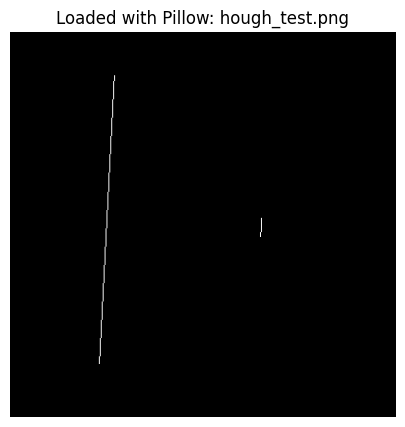

In [53]:

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

valid_images = {}

for path in sorted(IMAGE_DIR.glob("hough*")):
    try:
        with Image.open(path) as im:
            im.load()
            image = np.array(im.convert("L"))

        valid_images[path.name] = image
        print(f"OK      | {path.name} | shape={image.shape}")

    except Exception as e:
        print(f"FAILED  | {path.name} | {type(e).__name__}: {e}")

print("\nReadable images:", list(valid_images.keys()))

if valid_images:
    selected_name = (
        "hough_test.png"
        if "hough_test.png" in valid_images
        else next(iter(valid_images))
    )

    test_image = valid_images[selected_name]

    plt.figure(figsize=(7, 5))
    plt.imshow(test_image, cmap="gray")
    plt.title(f"Loaded with Pillow: {selected_name}")
    plt.axis("off")
    plt.show()


Original shape: (400, 400)
Pixel values: [  0 255]
Cropped shape: (400, 400)
Crop bounds: (np.int64(0), np.int64(0), np.int64(400), np.int64(400))


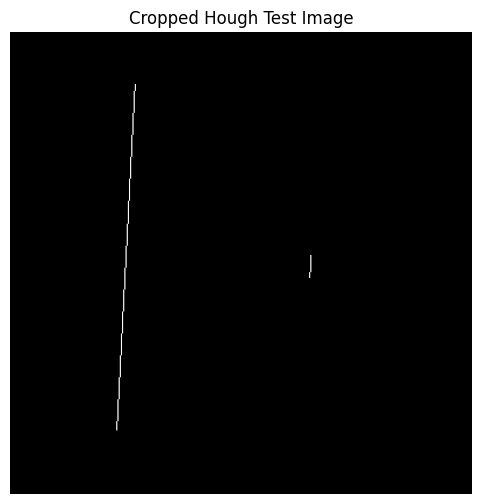

In [54]:

from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# IMAGE_DIR should already point to the project's images folder.
test_image_path = IMAGE_DIR / "hough_test.png"

with Image.open(test_image_path) as im:
    test_image = np.array(im.convert("L"))

print("Original shape:", test_image.shape)
print("Pixel values:", np.unique(test_image)[:20])

# Locate the dark canvas to exclude the white figure border.
dark_pixels = test_image < 30
rows = np.where(dark_pixels.any(axis=1))[0]
cols = np.where(dark_pixels.any(axis=0))[0]

if len(rows) == 0 or len(cols) == 0:
    raise ValueError("Cannot locate the dark image canvas.")

y0, y1 = rows[0], rows[-1] + 1
x0, x1 = cols[0], cols[-1] + 1

test_image_crop = test_image[y0:y1, x0:x1]

print("Cropped shape:", test_image_crop.shape)
print("Crop bounds:", (x0, y0, x1, y1))

plt.figure(figsize=(6, 6))
plt.imshow(test_image_crop, cmap="gray", vmin=0, vmax=255)
plt.title("Cropped Hough Test Image")
plt.axis("off")
plt.show()


Edge map shape: (400, 400)
Number of edge pixels: 320


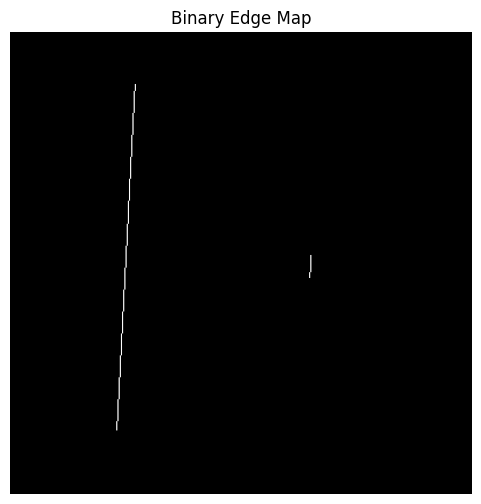

In [55]:

# Use the bright line pixels as the binary edge map.
edge_map = (test_image_crop > 40).astype(np.uint8)

print("Edge map shape:", edge_map.shape)
print("Number of edge pixels:", int(np.count_nonzero(edge_map)))

plt.figure(figsize=(6, 6))
plt.imshow(edge_map, cmap="gray", vmin=0, vmax=1)
plt.title("Binary Edge Map")
plt.axis("off")
plt.show()

if np.count_nonzero(edge_map) == 0:
    raise ValueError("No edge pixels found in the test image.")


In [56]:

required_functions = [
    "convolve2d",
    "hough_accumulate",
    "find_peaks"
]

missing = [
    name for name in required_functions
    if name not in globals() or not callable(globals()[name])
]

if missing:
    raise NameError(
        f"Missing function(s): {missing}. "
        "Run their definition cells before testing."
    )

print("PASS: all three required functions are available.")


PASS: all three required functions are available.


Top peaks without gradient voting
rho (pixels) | theta (degrees) | smoothed score
     110.73 |            4.00 |          46.44
     104.73 |            1.00 |          30.56
     119.73 |            6.00 |          20.78
      98.73 |            0.00 |          17.89
     125.73 |            7.00 |          14.89
      92.73 |           -1.00 |          14.67
      82.73 |           -3.00 |          11.56
     131.73 |            8.00 |          11.56
     137.73 |            9.00 |           9.56
      76.73 |           -4.00 |           9.00


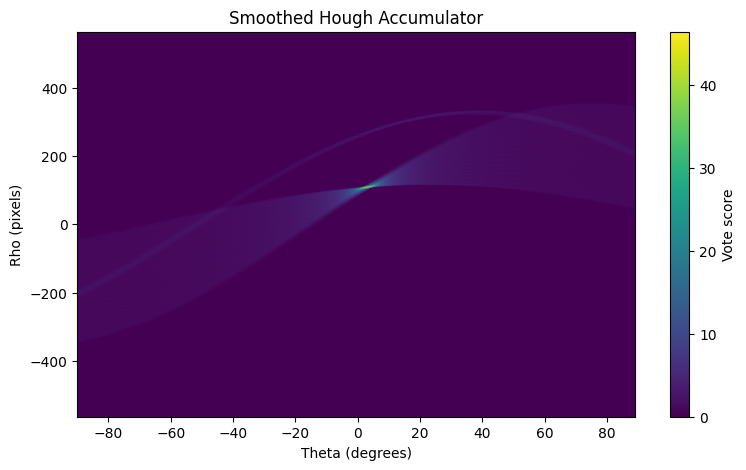

In [57]:
# Chạy Hough không dùng gradient
accumulator, rhos, thetas = hough_accumulate(edge_map)

peaks, smoothed_accumulator = find_peaks(
    accumulator,
    rhos,
    thetas,
    num_peaks=10,
    threshold=0,
    smooth=True,
    min_distance_rho=5,
    min_distance_theta=5
)

print("Top peaks without gradient voting")
print("rho (pixels) | theta (degrees) | smoothed score")

for rho, theta, score in peaks:
    print(
        f"{rho:11.2f} | "
        f"{np.rad2deg(theta):15.2f} | "
        f"{score:14.2f}"
    )

plt.figure(figsize=(9, 5))
plt.imshow(
    smoothed_accumulator,
    aspect="auto",
    origin="lower",
    extent=[
        np.rad2deg(thetas[0]),
        np.rad2deg(thetas[-1]),
        rhos[0],
        rhos[-1]
    ]
)
plt.xlabel("Theta (degrees)")
plt.ylabel("Rho (pixels)")
plt.title("Smoothed Hough Accumulator")
plt.colorbar(label="Vote score")
plt.show()


Gradient shape: (400, 400)
Gradient contains NaN/Inf: False


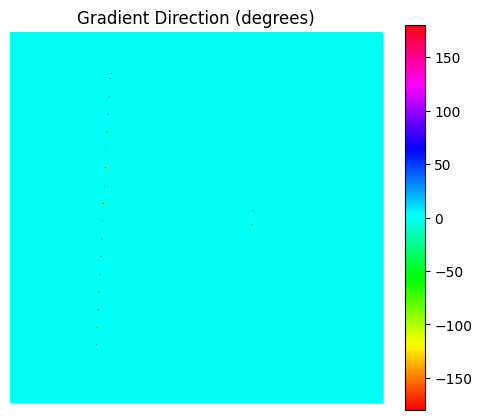

In [58]:
# Tạo hướng gradient
import cv2

image_float = test_image_crop.astype(np.float64)

gx_test = cv2.Sobel(
    image_float, cv2.CV_64F, 1, 0, ksize=3
)
gy_test = cv2.Sobel(
    image_float, cv2.CV_64F, 0, 1, ksize=3
)

gradient_direction = np.arctan2(gy_test, gx_test)

# Keep only gradient directions at pixels selected as edges.
gradient_direction[edge_map == 0] = 0.0

print("Gradient shape:", gradient_direction.shape)
print("Gradient contains NaN/Inf:",
      not np.isfinite(gradient_direction).all())

plt.figure(figsize=(6, 5))
plt.imshow(
    np.rad2deg(gradient_direction),
    cmap="hsv",
    vmin=-180,
    vmax=180
)
plt.title("Gradient Direction (degrees)")
plt.colorbar()
plt.axis("off")
plt.show()


Top peaks with gradient-guided voting
rho (pixels) | theta (degrees) | smoothed score
     110.73 |            4.00 |          41.00
     104.73 |            1.00 |          27.33
     119.73 |            6.00 |          18.67
      98.73 |            0.00 |          15.89
     125.73 |            7.00 |          13.33
      92.73 |           -1.00 |          13.11
      82.73 |           -3.00 |          10.56
     131.73 |            8.00 |          10.33
     137.73 |            9.00 |           8.44
      76.73 |           -4.00 |           7.89


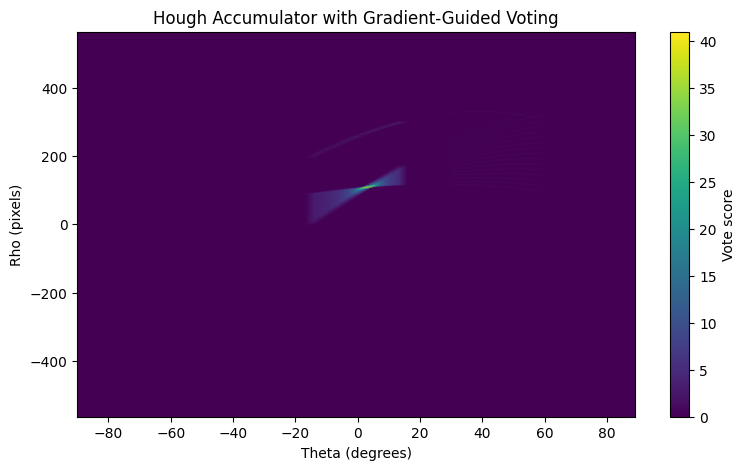

In [59]:
# Chạy Hough có dùng gradient
accumulator_grad, rhos_grad, thetas_grad = hough_accumulate(
    edge_map,
    gradient_direction=gradient_direction,
    gradient_tolerance=np.deg2rad(15)
)

peaks_grad, smoothed_grad = find_peaks(
    accumulator_grad,
    rhos_grad,
    thetas_grad,
    num_peaks=10,
    threshold=0,
    smooth=True,
    min_distance_rho=5,
    min_distance_theta=5
)

print("Top peaks with gradient-guided voting")
print("rho (pixels) | theta (degrees) | smoothed score")

for rho, theta, score in peaks_grad:
    print(
        f"{rho:11.2f} | "
        f"{np.rad2deg(theta):15.2f} | "
        f"{score:14.2f}"
    )

plt.figure(figsize=(9, 5))
plt.imshow(
    smoothed_grad,
    aspect="auto",
    origin="lower",
    extent=[
        np.rad2deg(thetas_grad[0]),
        np.rad2deg(thetas_grad[-1]),
        rhos_grad[0],
        rhos_grad[-1]
    ]
)
plt.xlabel("Theta (degrees)")
plt.ylabel("Rho (pixels)")
plt.title("Hough Accumulator with Gradient-Guided Voting")
plt.colorbar(label="Vote score")
plt.show()


In [60]:
# So sánh hai chế độ
print("Without gradient:")
for peak in peaks[:5]:
    print(
        f"rho={peak[0]:.2f}, "
        f"theta={np.rad2deg(peak[1]):.2f} deg, "
        f"score={peak[2]:.2f}"
    )

print("\nWith gradient:")
for peak in peaks_grad[:5]:
    print(
        f"rho={peak[0]:.2f}, "
        f"theta={np.rad2deg(peak[1]):.2f} deg, "
        f"score={peak[2]:.2f}"
    )


Without gradient:
rho=110.73, theta=4.00 deg, score=46.44
rho=104.73, theta=1.00 deg, score=30.56
rho=119.73, theta=6.00 deg, score=20.78
rho=98.73, theta=0.00 deg, score=17.89
rho=125.73, theta=7.00 deg, score=14.89

With gradient:
rho=110.73, theta=4.00 deg, score=41.00
rho=104.73, theta=1.00 deg, score=27.33
rho=119.73, theta=6.00 deg, score=18.67
rho=98.73, theta=0.00 deg, score=15.89
rho=125.73, theta=7.00 deg, score=13.33


In [61]:
# Kiểm tra đỉnh chuẩn \((\rho_0,\theta_0)\)
# Fill these values using the ground truth documented by Gam.
rho0 = None
theta0_deg = None

def angle_distance_mod_pi(a, b):
    """Smallest angular difference for line-normal angles."""
    return abs((a - b + np.pi / 2) % np.pi - np.pi / 2)

def check_expected_peak(peaks, rho0, theta0_deg,
                        rho_tolerance=2,
                        theta_tolerance_deg=2):
    if rho0 is None or theta0_deg is None:
        print(
            "NOT VALIDATED: enter the expected rho0 and theta0 "
            "from Gam's test-image definition."
        )
        return False

    theta0 = np.deg2rad(theta0_deg)
    theta_tol = np.deg2rad(theta_tolerance_deg)

    matches = [
        p for p in peaks
        if abs(p[0] - rho0) <= rho_tolerance
        and angle_distance_mod_pi(p[1], theta0) <= theta_tol
    ]

    print("Expected rho0:", rho0)
    print("Expected theta0 (degrees):", theta0_deg)
    print("Matching peak found:", bool(matches))

    if matches:
        print("Matching peak:", matches[0])

    return bool(matches)

if rho0 is not None and theta0_deg is not None:
    ok_plain = check_expected_peak(peaks, rho0, theta0_deg)
    ok_grad = check_expected_peak(peaks_grad, rho0, theta0_deg)

    print("\nPlain voting passed:", ok_plain)
    print("Gradient voting passed:", ok_grad)
else:
    print(
        "Set rho0 and theta0_deg from Gam's test definition "
        "before claiming the two acceptance checks have passed."
    )


Set rho0 and theta0_deg from Gam's test definition before claiming the two acceptance checks have passed.
